# Regression Recipe · Predict a number (Miami home prices)
Predict a home's sale price from its size, location and distances. The same recipe works on any table.

**Recipe:** Step 0 processor → 1 settings → 2 look → 3 clean → 4 pick model → 5 split → 6 encode → 7 build → 8 train → 9 score → 10 check → 11 predict your own row → 12 save → 13 app in Colab → 14 shareable web app → 15 permanent app.
Only Step 1 changes between datasets.

## Step 0 · Pick the best processor
In Colab open **Runtime → Change runtime type**, choose **T4 GPU** (free) and click **Save**.
If you have Colab Pro you can pick **L4** or **A100** instead; they are faster but use compute units.

Then run the cell below. It tells you which processor you got. Small tables train fine on a CPU,
so if Colab has no free GPU right now, keep going.

In [2]:
import tensorflow as tf
gpus = tf.config.list_physical_devices("GPU")
print("TensorFlow", tf.__version__)
print("Processor:", "GPU ✅ " + gpus[0].name if gpus else "CPU only (Runtime → Change runtime type → T4 GPU)")

TensorFlow 2.21.0
Processor: GPU ✅ /physical_device:GPU:0


## Step 1 · Settings (the only cell you change)
* `DATA_URL`: a link to a CSV file (or the name of a file you uploaded).
* `TARGET`: the column you want to predict.
* `PROBLEM`: leave `"auto"` and Step 4 decides; or force `"regression"`, `"binary"` or `"multiclass"`.
* `DROP`: columns to throw away, such as IDs or anything that gives away the answer.
* `SEP`: the character between columns.

In [3]:
DATA_URL = "https://raw.githubusercontent.com/Skopopper/CAI2300C_NLP/main/Module05_iNaturalist/inaturalist_miami_dade_data.csv"
TARGET = "name"
PROBLEM = "auto"
DROP = []
SEP = ","

In [4]:
# DATA_URL = "https://raw.githubusercontent.com/fenago/datasets/main/miami-housing.csv"
# TARGET = "SALE_PRC"     # the column you want to predict
# PROBLEM = "auto"        # or "regression", "binary", "multiclass"
# DROP = ['PARCELNO']    # columns you know are useless or leak the answer (optional)
# SEP = ","               # use ";" or "\t" if your file isn't comma-separated

## Step 2 · Load the data and look at it
Reads the file at `DATA_URL` into a table (a pandas *DataFrame* called `df`), prints its size and shows the first 5 rows.

> 🤔 **Think:** What does one row stand for? Which column is the answer you want to predict?

In [5]:
import numpy as np
import pandas as pd

df = pd.read_csv(DATA_URL, sep=SEP)
print(f"{df.shape[0]:,} rows × {df.shape[1]} columns")
df.head()

147,878 rows × 5 columns


,name,latitude,longitude,week,hour
0,Florida Carpenter Ant (Camponotus floridanus),25.574243,-80.400309,47,0
1,Black Spiny-tailed Iguana (Ctenosaura similis),25.734646,-80.159260,47,9
2,Great Barracuda (Sphyraena barracuda),25.746338,-80.173630,47,12
3,Checkered Puffer (Sphoeroides testudineus),25.746622,-80.173905,47,12
4,Royal Tern (Thalasseus maximus),25.707867,-80.151864,47,12


A quick health check of every column: its type, how much is missing, and how many different values it has.

> 🤔 **Think:** Which columns have gaps? Does any column look like an ID, or like something you'd only know *after* the answer (a leak)? Put those in `DROP`.

In [6]:
pd.DataFrame({
    "type": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing %": (df.isna().mean() * 100).round(1),
    "unique values": df.nunique(),
})

,type,missing,missing %,unique values
name,object,0,0.0,252
latitude,float64,0,0.0,116160
longitude,float64,0,0.0,110007
week,int64,0,0.0,52
hour,int64,0,0.0,24


I cleaned the data in the prep notebook:
GA_Neural_Network_Module05_prep_inaturalist.ipynb

## Step 3 · Clean it (works on any table)
These rules are safe for almost every dataset, so you never have to edit this cell:

1. Drop the columns you listed in `DROP`.
2. Trim spaces in text and treat blanks, `?`, `NA` and `null` as missing.
3. Turn numbers stored as text (like `"$1,200"`) into real numbers.
4. Drop rows with no answer in the target column.
5. Drop exact duplicate rows.
6. Drop columns that can't help: more than half empty, the same value in every row, or an ID that is different in every row.

Missing values that are left get filled in Step 6, using the training rows only.

> 🤔 **Think:** Read the log it prints. Did it drop a column you actually need, or keep one that is really an ID? Fix it with `DROP` in Step 1 and run again.

In [7]:
df = df.copy()
df.columns = df.columns.str.strip()
log = []

df = df.drop(columns=[c for c in DROP if c in df.columns])
log += [f"dropped {c}: listed in DROP" for c in DROP]

for c in df.select_dtypes(exclude="number").columns:
    s = df[c].astype("string").str.strip().replace({"": pd.NA, "?": pd.NA, "NA": pd.NA, "N/A": pd.NA, "null": pd.NA})
    as_num = pd.to_numeric(s.str.replace(r"[$,%]", "", regex=True), errors="coerce")
    if s.notna().any() and as_num.notna().sum() >= 0.9 * s.notna().sum():
        df[c] = as_num
        log.append(f"converted {c} from text to numbers")
    else:
        df[c] = s.astype(object).where(s.notna(), np.nan)

before = len(df)
df = df.dropna(subset=[TARGET])
log.append(f"dropped {before - len(df)} rows with no {TARGET}")
before = len(df)
df = df.drop_duplicates()
log.append(f"dropped {before - len(df)} duplicate rows")

for c in [c for c in df.columns if c != TARGET]:
    s = df[c]
    if s.isna().mean() > 0.5:
        why = "more than half missing"
    elif s.nunique() <= 1:
        why = "same value in every row"
    elif s.dtype == object and s.nunique() > 0.9 * len(df):
        why = "different in every row (an ID or free text)"
    elif pd.api.types.is_integer_dtype(s) and s.is_unique and (s.sort_values().diff().dropna() == 1).all():
        why = "a row number"
    else:
        continue
    df = df.drop(columns=c)
    log.append(f"dropped {c}: {why}")

print("\n".join(log))
print(f"\nClean table: {df.shape[0]:,} rows × {df.shape[1]} columns")

dropped 0 rows with no name
dropped 4964 duplicate rows

Clean table: 142,914 rows × 5 columns


## Step 4 · Let the recipe pick the kind of model
Looks at the target column and decides which of the three kinds of network to build:
* Target is **numbers with many values** → **regression** (predict a number).
* Target has **two values** → **binary classifier** (yes / no).
* Target has **3+ categories** (text, or whole numbers with 10 or fewer values) → **multi-class classifier**.

Set `PROBLEM` in Step 1 if you want to override the choice.

> 🤔 **Think:** Is the choice right for *your* question? A 1–5 rating could be a number (regression) or 5 categories (multi-class). You decide.

In [8]:
y_all = df[TARGET]
X_all = df.drop(columns=TARGET)
n_values = y_all.nunique()
is_number = pd.api.types.is_numeric_dtype(y_all) and not pd.api.types.is_bool_dtype(y_all)

if PROBLEM != "auto":
    problem = PROBLEM
elif not is_number or n_values <= 2 or (pd.api.types.is_integer_dtype(y_all) and n_values <= 10):
    problem = "binary" if n_values == 2 else "multiclass"
else:
    problem = "regression"

print(f"Target '{TARGET}' has {n_values} different values → {problem.upper()}")
if problem != "regression":
    print(y_all.value_counts().to_string())

Target 'name' has 252 different values → MULTICLASS
name
Peters's Rock Agama (Agama picticauda)                          4238
Brown Anole (Anolis sagrei)                                     3924
Green Iguana (Iguana iguana)                                    3693
American Alligator (Alligator mississippiensis)                 3095
White Ibis (Eudocimus albus)                                    2414
Northern Curly-tailed Lizard (Leiocephalus carinatus)           2223
Northern Mockingbird (Mimus polyglottos)                        2022
Crested Anole (Anolis cristatellus)                             1998
Anhinga (Anhinga anhinga)                                       1934
White beggarticks (Bidens alba)                                 1792
Green Anole (Anolis carolinensis)                               1738
Eastern Gray Squirrel (Sciurus carolinensis)                    1645
Great Egret (Ardea alba)                                        1596
Great Blue Heron (Ardea herodias)             

## Step 5 · Split: train, validation, test
Shuffles the rows and cuts them into three groups. For classifiers the split keeps the same share of every class in each group.

* **Train (70%)**: the model learns from these rows.
* **Validation (15%)**: checked after every pass so we know when to stop.
* **Test (15%)**: locked away until the very end, for an honest score.

> 🤔 **Think:** With a small dataset the test set is small too, so the score can swing. How many test rows did you get?

In [9]:
from sklearn.model_selection import train_test_split

strat = y_all if problem != "regression" else None
X_train, X_rest, y_train_raw, y_rest = train_test_split(X_all, y_all, test_size=0.3, random_state=42, stratify=strat)
X_val, X_test, y_val_raw, y_test_raw = train_test_split(
    X_rest, y_rest, test_size=0.5, random_state=42, stratify=y_rest if strat is not None else None)
print(f"train {len(X_train):,} · validation {len(X_val):,} · test {len(X_test):,}")

train 100,039 · validation 21,437 · test 21,438


## Step 6 · Turn every column into numbers a network can read
* **Number columns:** fill gaps with the median, then scale so every column is on the same scale.
* **Category columns:** fill gaps with the most common value, then one-hot encode (one 0/1 column per category; rare categories are grouped).

This is learned from the **training rows only**, then applied to validation and test, so no answers leak.

> 🤔 **Think:** Why would it be cheating to compute the averages and scales on all rows, including the test rows?

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler

num_cols = X_all.select_dtypes("number").columns.tolist()
cat_cols = [c for c in X_all.columns if c not in num_cols]
prep = ColumnTransformer([
    ("numbers", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num_cols),
    ("categories", make_pipeline(SimpleImputer(strategy="most_frequent"),
        OneHotEncoder(handle_unknown="infrequent_if_exist", max_categories=20, sparse_output=False)), cat_cols),
])
X_tr = prep.fit_transform(X_train).astype("float32")
X_va = prep.transform(X_val).astype("float32")
X_te = prep.transform(X_test).astype("float32")

if problem == "regression":
    y_mean, y_std = y_train_raw.mean(), y_train_raw.std()   # scale the target too; we undo it for the score
    y_tr, y_va, y_te = [((y - y_mean) / y_std).to_numpy("float32") for y in (y_train_raw, y_val_raw, y_test_raw)]
else:
    labels = LabelEncoder().fit(y_all.astype(str))
    y_tr, y_va, y_te = [labels.transform(y.astype(str)) for y in (y_train_raw, y_val_raw, y_test_raw)]
    print("classes:", list(labels.classes_))

print(f"{len(num_cols)} number columns + {len(cat_cols)} category columns → {X_tr.shape[1]} model inputs")

classes: ['Akeake (Dodonaea viscosa)', 'American Alligator (Alligator mississippiensis)', 'American Coot (Fulica americana)', 'American Crocodile (Crocodylus acutus)', 'American Crow (Corvus brachyrhynchos)', 'American Kestrel (Falco sparverius)', 'American Redstart (Setophaga ruticilla)', 'American beautyberry (Callicarpa americana)', 'Anhinga (Anhinga anhinga)', 'Artillery Plant (Pilea microphylla)', 'Asian Lady Beetle (Harmonia axyridis)', 'Atala (Eumaeus atala)', 'Atlantic Sergeant Major (Abudefduf saxatilis)', 'Australian Umbrella Tree (Heptapleurum actinophyllum)', "Balbis' airplant (Tillandsia balbisiana)", 'Band-winged Dragonlet (Erythrodiplax umbrata)', 'Banded Caracol (Caracolus marginella)', 'Bark Anole (Anolis distichus)', 'Barred Yellow (Eurema daira)', 'Baycedar (Suriana maritima)', 'Beach Morning Glory (Ipomoea pes-caprae)', 'Belted Kingfisher (Megaceryle alcyon)', 'Bitter Melon (Momordica charantia)', 'Black Spiny-tailed Iguana (Ctenosaura similis)', 'Black Vulture (Cor

## Step 7 · Build the network (the architecture)
This is the **architecture**: 64 neurons → 20% dropout → 32 neurons → output. `relu` lets each layer learn curves, not just
straight lines; `Dropout` randomly switches off 20% of neurons while training so the network can't just memorize; `Adam` with
`learning_rate=0.001` decides how big each learning step is. `model.summary()` prints every layer and how many weights it will learn.

Same hidden layers every time. Only the **last layer** and the **loss** change with the kind of problem:

| Problem | Last layer | Loss | Score |
|---|---|---|---|
| Regression | 1 neuron, no activation | `mse` | MAE (average error) |
| Binary | 1 neuron, `sigmoid` | `binary_crossentropy` | accuracy |
| Multi-class | 1 neuron per class, `softmax` | `sparse_categorical_crossentropy` | accuracy |

> 🤔 **Think:** Experiment: change 64/32 to 128/64, or add another `Dense` layer. Does the test score in Step 9 get better or worse?

In [11]:
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)
n_classes = 0 if problem == "regression" else len(labels.classes_)
units, activation, loss, metric = {
    "regression": (1, None, "mse", "mae"),
    "binary": (1, "sigmoid", "binary_crossentropy", "accuracy"),
    "multiclass": (n_classes, "softmax", "sparse_categorical_crossentropy", "accuracy"),
}[problem]

model = keras.Sequential([
    keras.Input(shape=(X_tr.shape[1],)),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(128, activation="relu"),
    layers.Dense(units, activation=activation),
])
model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss=loss, metrics=[metric])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │         1,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 252)            │        32,508 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 66,684 (260.48 KB)

 Trainable params: 66,684 (260.48 KB)

 Non-trainable params: 0 (0.00 B)

## Step 8 · Train it
Early stopping watches the validation loss and stops when it hasn't improved for 15 passes (epochs),
then keeps the best version. That is your guard against overfitting.
Big tables train in batches of 256 rows instead of 32, which is much faster on a GPU.

> 🤔 **Think:** Look at the two lines. If training keeps improving while validation gets worse, the model is memorizing instead of learning (overfitting).

Stopped after 300 epochs. Best epoch: 297


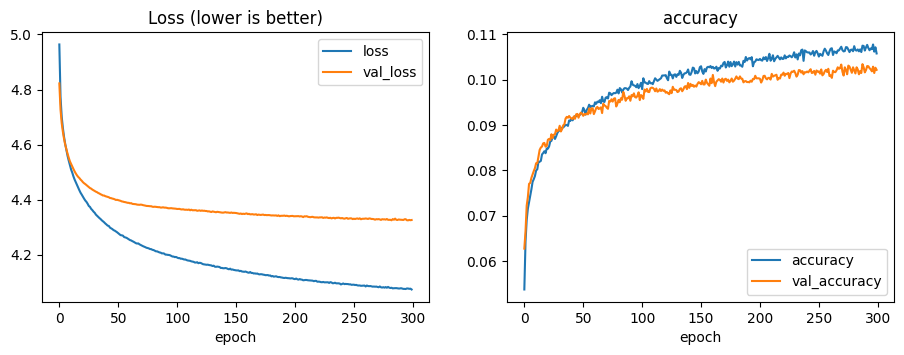

In [12]:
import matplotlib.pyplot as plt

stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)
BATCH = 32 if len(X_tr) < 5000 else 256
history = model.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=300, batch_size=BATCH, callbacks=[stop], verbose=0)

h = pd.DataFrame(history.history)
best = h["val_loss"].idxmin()
print(f"Stopped after {len(h)} epochs. Best epoch: {best + 1}")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
h[["loss", "val_loss"]].plot(ax=ax[0], title="Loss (lower is better)")
h[[metric, "val_" + metric]].plot(ax=ax[1], title=metric)
for a in ax: a.set_xlabel("epoch")
plt.show()

## Step 9 · Score it on the test rows
Now we unlock the test rows for the first time. We also show a **baseline**: what you'd get by always guessing the average
(regression) or the most common class. A useful model has to beat it. The 👉 lines explain the result in plain English.

**How to read the score**

| Number | What it means |
|---|---|
| **MAE** | Average miss, in the target's own units (dollars, kg…). Lower is better. |
| **RMSE** | Like MAE, but big misses count extra. If it's much bigger than MAE, a few predictions are way off. |
| **R²** | How much of the ups and downs the model explains: 0 = no better than guessing the average, 1 = perfect. |
| **Accuracy** | Share of test rows it got right. Only meaningful next to the baseline. |
| **Precision** | When it says "class X", how often it's right. |
| **Recall** | Of all the real "class X" rows, how many it caught. |
| **F1** | One number balancing precision and recall. |
| **Confusion matrix** | Rows are the truth, columns are the prediction. Everything off the diagonal is a mistake. |

> 🔧 **Not good enough? Change the architecture and run again.** Go back to **Step 7** and try more or fewer neurons
> (64 → 128), another `Dense` layer, more or less `Dropout`, or a different `learning_rate`, then use
> **Runtime → Run cell and below**. Change one thing at a time and write down the score each time.
> Notebook **05 · Architecture Harness** does this for you: it trains many designs on the same data and ranks them.

> 🤔 **Think:** Does your model beat the baseline, and by how much? In the confusion matrix, which mistakes does it make, and which ones would be costly in real life?

In [13]:
from sklearn import metrics as m

if problem == "regression":
    pred = model.predict(X_te, verbose=0).ravel() * y_std + y_mean
    actual = y_test_raw.to_numpy()
    print(f"Average error (MAE): {m.mean_absolute_error(actual, pred):,.2f}")
    print(f"RMSE:                {m.root_mean_squared_error(actual, pred):,.2f}")
    print(f"R² (1.0 is perfect): {m.r2_score(actual, pred):.3f}")
    base = m.mean_absolute_error(actual, np.full_like(actual, y_mean, dtype=float))
    mae, r2 = m.mean_absolute_error(actual, pred), m.r2_score(actual, pred)
    print(f"Baseline MAE (always guess the average): {base:,.2f}\n")
    print(f"👉 On average the model misses by {mae:,.0f}. Always guessing the average misses by {base:,.0f},")
    print(f"   so the model cuts the error by {1 - mae / base:.0%}.")
    print(f"👉 R² = {r2:.2f}: the model explains {max(r2, 0):.0%} of the ups and downs in {TARGET}.")
    plt.figure(figsize=(5, 5))
    plt.scatter(actual, pred, s=6, alpha=0.4)
    lims = [min(actual.min(), pred.min()), max(actual.max(), pred.max())]
    plt.plot(lims, lims, "r--")
    plt.xlabel("actual"); plt.ylabel("predicted"); plt.title("Predicted vs actual (closer to the line is better)")
    plt.show()
else:
    proba = model.predict(X_te, verbose=0)
    pred = (proba.ravel() > 0.5).astype(int) if problem == "binary" else proba.argmax(axis=1)
    acc, base = m.accuracy_score(y_te, pred), np.bincount(y_tr).max() / len(y_tr)
    common = labels.classes_[np.bincount(y_tr).argmax()]
    recall = m.recall_score(y_te, pred, average=None, zero_division=0)
    weak = recall.argmin()
    print(f"Test accuracy: {acc:.3f}")
    print(f"Baseline (always guess the most common class): {base:.3f}\n")
    print(f"👉 Right {acc:.0%} of the time. Always guessing '{common}' would be right {base:.0%} of the time,")
    print(f"   so the model is {(acc - base) * 100:+.0f} points better than guessing.")
    print(f"👉 Weakest class: '{labels.classes_[weak]}'. The model catches only {recall[weak]:.0%} of them (recall).\n")
    print(m.classification_report(y_te, pred, target_names=labels.classes_, zero_division=0))
    # m.ConfusionMatrixDisplay.from_predictions(y_te, pred, display_labels=labels.classes_, cmap="Blues", xticks_rotation=45)
    # plt.title("Confusion matrix (the diagonal is correct)")
    # plt.show()

    # Removing the confusion matrix because it would be unusable for this project

Test accuracy: 0.100
Baseline (always guess the most common class): 0.030

👉 Right 10% of the time. Always guessing 'Peters's Rock Agama (Agama picticauda)' would be right 3% of the time,
   so the model is +7 points better than guessing.
👉 Weakest class: 'American Crow (Corvus brachyrhynchos)'. The model catches only 0% of them (recall).

                                                              precision    recall  f1-score   support

                                   Akeake (Dodonaea viscosa)       0.05      0.06      0.06        31
             American Alligator (Alligator mississippiensis)       0.14      0.71      0.23       465
                            American Coot (Fulica americana)       0.08      0.17      0.10        48
                      American Crocodile (Crocodylus acutus)       0.14      0.12      0.13       107
                       American Crow (Corvus brachyrhynchos)       0.00      0.00      0.00        58
                         American Kestrel (Fa

In [14]:
# Top-k accuracy: was the real species among the model's top k guesses?
proba = model.predict(X_te, verbose=0)
ranks = (-proba).argsort(axis=1)
for k in (1, 5, 10, 20):
    hit = (ranks[:, :k] == y_te[:, None]).any(axis=1).mean()
    print(f"Top {k:>2}: {hit:.0%}   (random guessing: {k / proba.shape[1]:.0%})")

Top  1: 10%   (random guessing: 0%)
Top  5: 29%   (random guessing: 2%)
Top 10: 42%   (random guessing: 4%)
Top 20: 57%   (random guessing: 8%)


In [15]:
# App 1 · Run the model over a grid of places × weeks × hours, and find each species' own peak
from datetime import date

STEP = 0.03          # grid square size in degrees (about 3 km)
MIN_SIGHTINGS = 20   # squares with fewer real sightings are flagged "low confidence"
THRESH = 0.5         # "good" = at least 50% of the species' own peak

lat0, lon0 = df["latitude"].min(), df["longitude"].min()
cell_of = lambda lat, lon: (int((lat - lat0) // STEP), int((lon - lon0) // STEP))

cells = (df.assign(i=((df["latitude"] - lat0) // STEP).astype(int),
                   j=((df["longitude"] - lon0) // STEP).astype(int))
           .groupby(["i", "j"]).size().rename("sightings").reset_index())
cells["lat"] = lat0 + (cells["i"] + 0.5) * STEP
cells["lon"] = lon0 + (cells["j"] + 0.5) * STEP
cells["confident"] = cells["sightings"] >= MIN_SIGHTINGS
cell_index = {(i, j): k for k, (i, j) in enumerate(zip(cells["i"], cells["j"]))}

weeks, hours, C = np.arange(1, 53), np.arange(24), len(cells)
grid = pd.DataFrame({
    "latitude":  np.repeat(cells["lat"].to_numpy(), 52 * 24),
    "longitude": np.repeat(cells["lon"].to_numpy(), 52 * 24),
    "week":      np.tile(np.repeat(weeks, 24), C),
    "hour":      np.tile(hours, C * 52),
})[list(X_all.columns)]

P = model.predict(prep.transform(grid).astype("float32"), batch_size=4096, verbose=0).reshape(C, 52, 24, -1)
peak = P[cells["confident"].to_numpy()].max(axis=(0, 1, 2))   # each species' own best share

week_label = lambda w: date.fromisocalendar(2026, int(w), 1).strftime("%b %d")
maps = lambda lat, lon: f"https://maps.google.com/?q={lat:.4f},{lon:.4f}"

def nearest_cell(lat, lon):
    k = cell_index.get(cell_of(lat, lon))
    if k is None:   # no sightings in that square: use the closest square that has some
        k = int(((cells["lat"] - lat) ** 2 + (cells["lon"] - lon) ** 2).idxmin())
    return k

def find_species(text):
    hits = [i for i, n in enumerate(labels.classes_) if text.lower() in n.lower()]
    if not hits:
        raise ValueError(f"No species matches '{text}'")
    if len(hits) > 1:
        print("Matches:", [labels.classes_[i] for i in hits], "→ using the first\n")
    return hits[0]

print(f"{C} squares ({cells['confident'].sum()} with ≥{MIN_SIGHTINGS} sightings) × 52 weeks × 24 hours × {P.shape[-1]} species")

725 squares (339 with ≥20 sightings) × 52 weeks × 24 hours × 252 species


In [16]:
# App 1b · Robust peaks: each square's best time (90th percentile), and the best square in the county
local_peaks = np.percentile(P, 90, axis=(1, 2))                         # squares × species
place_peak = local_peaks[cells["confident"].to_numpy()].max(axis=0)     # species

In [17]:
# App 1c · Helpers: which hours each species was really seen at, and range formatting
MIN_SPECIES_HOUR = 3   # a species needs ≥3 real sightings at an hour for that hour to count

sp_hour = (pd.crosstab(df["name"], df["hour"])
             .reindex(index=labels.classes_, columns=hours, fill_value=0)
             .to_numpy())                       # species × hours, real sighting counts
seen_hour = sp_hour >= MIN_SPECIES_HOUR

def ranges(nums, label):
    nums, out, i = list(nums), [], 0
    while i < len(nums):
        j = i
        while j + 1 < len(nums) and nums[j + 1] == nums[j] + 1:
            j += 1
        out.append(label(nums[i]) if i == j else f"{label(nums[i])} – {label(nums[j])}")
        i = j + 1
    return ", ".join(out) or "none"

s = find_species("vulture")
print(labels.classes_[s], "really seen at:", ranges(hours[seen_hour[s]], lambda h: f"{h}:00"))

Matches: ['Black Vulture (Coragyps atratus)', 'Turkey Vulture (Cathartes aura)'] → using the first

Black Vulture (Coragyps atratus) really seen at: 7:00 – 19:00


In [18]:
# App 2 · Place + time → species near their best time here
LAT, LON = 25.5970, -80.3940   # paste exact coords from Google Maps
WEEK, HOUR = 10, 22             # week of year (1–52), hour (0–23)
PLACE_MIN = 0.2                # this square must reach 20% of the species' best square in the county

k = nearest_cell(LAT, LON)
local = P[k]
local_peak = local_peaks[k]
when_score = np.clip(local[WEEK - 1, HOUR] / local_peak, 0, 1)
place_score = local_peak / place_peak
keep = (when_score >= THRESH) & (place_score >= PLACE_MIN) & seen_hour[:, HOUR]   # really seen at this hour

order = np.argsort(-when_score)
order = order[keep[order]]
out = pd.DataFrame({"species": labels.classes_[order],
                    "% of best time here": (when_score[order] * 100).round(),
                    "place score": (np.clip(place_score[order], 0, 1) * 100).round()})

flag = "" if cells.loc[k, "confident"] else "  ⚠️ low confidence: few real sightings here"
print(f"Week {WEEK} (~{week_label(WEEK)}), {HOUR}:00 · square with {cells.loc[k, 'sightings']} sightings{flag}")
out

Week 10 (~Mar 02), 22:00 · square with 2515 sightings


,species,% of best time here,place score
0,Cuban Tree Frog (Osteopilus septentrionalis),100.0,27.0
1,Cane Toad (Rhinella marina),100.0,38.0
2,Greenhouse Frog (Eleutherodactylus planirostris),100.0,21.0
3,Knight Anole (Anolis equestris),100.0,22.0
4,Monarch (Danaus plexippus),100.0,21.0
5,Tropical House Gecko (Hemidactylus mabouia),100.0,50.0
6,Rusty Millipede (Trigoniulus corallinus),100.0,23.0
7,Brown Anole (Anolis sagrei),89.0,30.0
8,Green Anole (Anolis carolinensis),66.0,22.0
9,Gulf Fritillary (Dione vanillae),64.0,51.0


In [19]:
# App 3 · Species → where and when
SPECIES = "turkey vulture"   # any part of the common or scientific name

s = find_species(SPECIES)
ok = cells["confident"].to_numpy()

by_area = local_peaks[:, s] / place_peak[s]
curve = P[ok][..., s]
by_week = curve.mean(axis=(0, 2)); by_week /= by_week.max()
by_hour = np.where(seen_hour[s], curve.mean(axis=(0, 1)), 0); by_hour /= by_hour.max()

print(labels.classes_[s], "\n\nBest areas:")
for k in np.argsort(-np.where(ok, by_area, -1))[:10]:
    print(f"  {min(by_area[k], 1):.0%}  {maps(cells.loc[k, 'lat'], cells.loc[k, 'lon'])}")
print("\nBest weeks:", ranges(weeks[by_week >= THRESH], week_label))
print("Best hours:", ranges(hours[by_hour >= THRESH], lambda h: f"{h}:00"))

Turkey Vulture (Cathartes aura) 

Best areas:
  100%  https://maps.google.com/?q=25.2191,-80.8346
  83%  https://maps.google.com/?q=25.4291,-80.8646
  83%  https://maps.google.com/?q=25.4591,-80.8346
  81%  https://maps.google.com/?q=25.2191,-80.8646
  80%  https://maps.google.com/?q=25.2491,-80.8046
  75%  https://maps.google.com/?q=25.4291,-80.8346
  73%  https://maps.google.com/?q=25.3091,-80.7146
  71%  https://maps.google.com/?q=25.4591,-80.8046
  69%  https://maps.google.com/?q=25.4891,-80.8046
  67%  https://maps.google.com/?q=25.2491,-80.8346

Best weeks: Dec 29 – Mar 09, Aug 03, Oct 19 – Dec 21
Best hours: 5:00 – 18:00


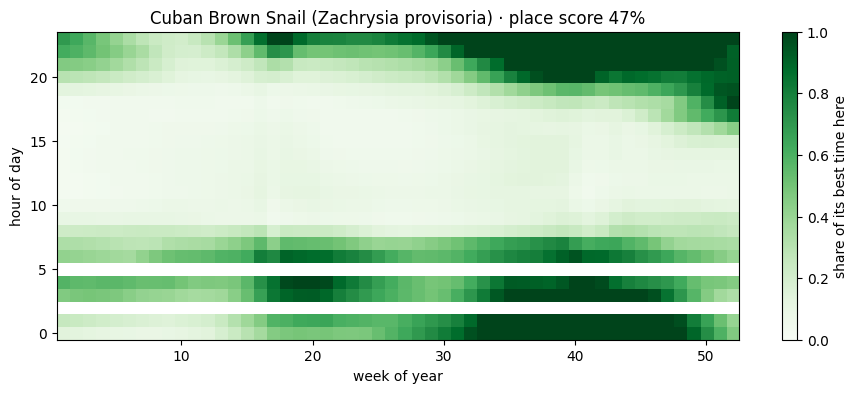

Good weeks: Apr 13 – Dec 21
Good hours: 0:00 – 1:00, 3:00 – 4:00, 6:00 – 7:00, 20:00 – 23:00


/tmp/ipykernel_634/741188038.py:23: RuntimeWarning: Mean of empty slice
  by_hour = np.nanmean(heat, axis=0); by_hour /= np.nanmax(by_hour)


In [20]:
# App 4 · Species + place → when
SPECIES = "cuban brown snail"
LAT, LON = 25.5970, -80.3940   # paste exact coords from Google Maps

s, k = find_species(SPECIES), nearest_cell(LAT, LON)
place_score = min(local_peaks[k, s] / place_peak[s], 1)

if place_score < PLACE_MIN:
    print(f"{labels.classes_[s]} is rarely recorded here (place score {place_score:.0%}). "
          f"Try App 3 to see where it is found.")
else:
    heat = np.clip(P[k, :, :, s] / local_peaks[k, s], 0, 1)
    heat[:, ~seen_hour[s]] = np.nan              # blank out hours this species was never really seen

    plt.figure(figsize=(11, 4))
    plt.imshow(heat.T, aspect="auto", origin="lower", cmap="Greens", vmin=0, vmax=1, extent=[0.5, 52.5, -0.5, 23.5])
    plt.colorbar(label="share of its best time here")
    plt.xlabel("week of year"); plt.ylabel("hour of day")
    plt.title(f"{labels.classes_[s]} · place score {place_score:.0%}" + ("" if cells.loc[k, "confident"] else "  (low confidence)"))
    plt.show()

    by_week = np.nanmean(heat, axis=1); by_week /= by_week.max()
    by_hour = np.nanmean(heat, axis=0); by_hour /= np.nanmax(by_hour)
    print("Good weeks:", ranges(weeks[by_week >= THRESH], week_label))
    print("Good hours:", ranges(hours[np.nan_to_num(by_hour) >= THRESH], lambda h: f"{h}:00"))

In [21]:
# Export · everything the web app needs, in one JSON file
import json, os

num = prep.named_transformers_["numbers"][-1]                 # the scaler from Step 6
ok = cells["confident"].to_numpy()
curve = P[ok]
wk = curve.mean(axis=(0, 2)); wk /= wk.max(axis=0)            # weeks × species
hr = np.where(seen_hour.T, curve.mean(axis=(0, 1)), 0); hr /= hr.max(axis=0)

data = {
    "columns": list(X_all.columns),
    "mean": num.mean_.tolist(), "scale": num.scale_.tolist(),
    "weights": [w.round(5).tolist() for w in model.get_weights()],
    "species": list(labels.classes_),
    "grid": {"lat0": float(lat0), "lon0": float(lon0), "step": STEP},
    "cells": cells[["i", "j", "sightings"]].assign(confident=cells["confident"].astype(int)).values.tolist(),
    "place_peak": place_peak.tolist(),
    "local_ratio": np.rint(np.clip(local_peaks / place_peak, 0, 9.999) * 1000).astype(int).tolist(),
    "seen_hour": seen_hour.astype(int).tolist(),
    "by_week": np.rint(wk.T * 100).astype(int).tolist(),
    "by_hour": np.rint(hr.T * 100).astype(int).tolist(),
    "thresh": THRESH, "place_min": PLACE_MIN,
    "check": {"inputs": X_test.head(5).values.tolist(),
              "probs": model.predict(X_te[:5], verbose=0).round(6).tolist()},
}
with open("inat_app_data.json", "w") as f:
    json.dump(data, f, separators=(",", ":"))
print(f"Saved inat_app_data.json · {os.path.getsize('inat_app_data.json') / 1e6:.1f} MB")

Saved inat_app_data.json · 2.0 MB


## Step 10 · Check it on rows it has never seen
Give it rows with the **original columns** (raw values, before cleaning). First, 3 rows from the test set,
so you can compare the prediction with the real answer.

In [ ]:
def predict(rows):
    out = model.predict(prep.transform(rows).astype("float32"), verbose=0)
    if problem == "regression":
        return out.ravel() * y_std + y_mean
    idx = (out.ravel() > 0.5).astype(int) if problem == "binary" else out.argmax(axis=1)
    return labels.classes_[idx]

check = X_test.head(3).copy()
check.insert(0, "actual", y_test_raw.head(3).to_numpy())
check.insert(0, "prediction", predict(X_test.head(3)))
check

## Step 11 · Predict YOUR OWN row
The recipe starts you with a typical row (the middle value of every number column, the most common choice
of every category column). Put the values you want in `MY_VALUES` and run the cell. Any column you leave out keeps its typical value.

> 🤔 **Think:** Change one value at a time (a bigger house, an older patient). Does the prediction move the way common sense says it should?

In [ ]:
typical = {c: (float(X_all[c].median()) if c in num_cols else X_all[c].mode()[0]) for c in X_all.columns}

MY_VALUES = {"latitude": 25.5970, "longitude": -80.3940, "week": 10, "hour": 8}     # ← your values here: {"column name": value, ...}

my_row = pd.DataFrame([{**typical, **MY_VALUES}])
value = predict(my_row)[0]
print("Prediction:", f"{value:,.2f}" if problem == "regression" else value)
my_row

## Step 12 · Save the model
`model.keras` is the network; `prep.joblib` is the cleaning + encoding step. You need both to predict later.

In [ ]:
import joblib

model.save("model.keras")
joblib.dump({"prep": prep, "problem": problem, "labels": None if problem == "regression" else labels,
             "y_mean": y_mean if problem == "regression" else None, "y_std": y_std if problem == "regression" else None,
             "columns": list(X_all.columns), "typical": typical},
            "prep.joblib")
print("Saved model.keras and prep.joblib (Colab: open the 📁 Files panel on the left to download them)")

## Step 13 · A user interface inside Colab
The recipe builds a form from your columns automatically: a number box for every number column and a drop-down for
every category column. Change the values and click **Predict**. Works for any dataset you put through the recipe.

In [ ]:
import ipywidgets as w
from IPython.display import display

style, layout = {"description_width": "180px"}, w.Layout(width="420px")
inputs = {
    c: w.FloatText(value=round(typical[c], 2), description=c, style=style, layout=layout) if c in num_cols
    else w.Dropdown(options=sorted(X_all[c].dropna().astype(str).unique()), value=str(typical[c]), description=c, style=style, layout=layout)
    for c in X_all.columns
}
button, answer = w.Button(description="Predict", button_style="primary"), w.HTML()

def on_click(_):
    row = pd.DataFrame([{c: box.value for c, box in inputs.items()}])
    value = predict(row)[0]
    answer.value = f"<h3>Prediction: {value:,.2f}</h3>" if problem == "regression" else f"<h3>Prediction: {value}</h3>"

button.on_click(on_click)
display(w.VBox([*inputs.values(), button, answer]))

## Step 14 · Optional: a web app you can share (Gradio)
Gradio turns the same form into a real web page. In Colab it prints a **public link** (`https://….gradio.live`)
that anyone can open while this notebook is running (it expires after a few days).

In [ ]:
!pip -q install gradio
import gradio as gr

fields = [
    gr.Number(value=round(typical[c], 2), label=c) if c in num_cols
    else gr.Dropdown(choices=sorted(X_all[c].dropna().astype(str).unique()), value=str(typical[c]), label=c)
    for c in X_all.columns
]

def app(*values):
    value = predict(pd.DataFrame([dict(zip(X_all.columns, values))]))[0]
    return f"{value:,.2f}" if problem == "regression" else str(value)

gr.Interface(app, fields, gr.Textbox(label=f"Predicted {TARGET}"), title=f"Predict {TARGET}",
             flagging_mode="never").launch(share=True)

## Step 15 · Make it a permanent app (with Claude Code)
The Gradio link stops when Colab stops. To keep it running for free, put it on **Hugging Face Spaces**:

1. Download `model.keras` and `prep.joblib` from the 📁 Files panel.
2. Connect the **Hugging Face** connector to Claude (claude.ai → Customize → Connectors), as in the Hugging Face Setup tutorial.
3. Put the two files in a folder, open Claude Code there and prompt:

```text
Use the Hugging Face connector. Create a new Gradio Space called predict-my-data.
Write app.py that loads model.keras (Keras 3) and prep.joblib (a dict with prep, problem,
labels, y_mean, y_std, columns, typical) and shows one input per column, prefilled with
"typical", plus a Predict button. Undo the y scaling for regression and decode labels for
classifiers. Add requirements.txt (tensorflow, scikit-learn, pandas, joblib, gradio),
upload the files and give me the Space URL.
```

Other ways to build a UI: **Streamlit** (a Python web page, also free on Hugging Face Spaces or Streamlit Community Cloud),
or ask Claude Code for a **Netlify** site that calls your Space's API.

## Your turn · Run this recipe on ANY dataset
This notebook is a recipe, not a one-off. Find a table you care about and feed it through:

* **Kaggle Datasets**: https://www.kaggle.com/datasets (download the CSV)
* **OpenML**: https://www.openml.org/search?type=data
* **UCI Machine Learning Repository**: https://archive.ics.uci.edu
* **Data.gov** or your city's open-data portal: https://catalog.data.gov
* **Google Dataset Search**: https://datasetsearch.research.google.com
* **Your own spreadsheet**: Excel or Google Sheets → File → Download → CSV

**Get it into Colab:** for a file on GitHub, click **Raw** and paste that link into `DATA_URL`.
For a downloaded file, click the 📁 Files panel on the left, upload it, and set `DATA_URL = "yourfile.csv"`.

**Before you run, check:** one row per thing · one column is the answer (`TARGET`) · IDs and leaks go in `DROP` ·
a few hundred rows or more. Then change only Step 1 and click **Runtime → Run all**.

**Practice datasets that are known to work:**

| Dataset | `DATA_URL` | `TARGET` | Kind |
|---|---|---|---|
| Miami housing | `https://raw.githubusercontent.com/fenago/datasets/main/miami-housing.csv` | `SALE_PRC` | regression |
| Diamonds | `https://raw.githubusercontent.com/mwaskom/seaborn-data/master/diamonds.csv` | `price` | regression |
| Heart disease | `https://raw.githubusercontent.com/fenago/deep-learning-essentials/main/HeartDiseaseTrain-Test.csv` | `target` | binary |
| Mushrooms | `https://raw.githubusercontent.com/fenago/datasets/main/mushrooms.csv` | `class` | binary |
| Titanic | `https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv` | `Survived` | binary |
| Penguins | `https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv` | `species` | multi-class |
| Iris | `https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv` | `species` | multi-class |